In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B12 – Phát Hiện Mã Độc Bằng K-Nearest Neighbors (KNN)
## Đặc Trưng Tĩnh PE Header – Dataset Malware-Benign

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════

# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
_name = "Malware-Benign.csv"
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR.parent / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR / "Dataset" / "malware-benignpe-files" / _name,
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
# Malware: 0 = file lành tính, 1 = mã độc
LABEL_COL = "Malware"
TARGET_NAMES = ["Benign", "Malware"]

# Cột hash chỉ để định danh file, không mang thông tin phân loại
ID_COL = "Hash_md5_Name"
META_COLS = []

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42
TEST_SIZE = 0.3
CV_FOLDS = 5

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ KNN
# ==========================
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]
METRICS = ["euclidean", "manhattan", "chebyshev"]
WEIGHTS = ["uniform", "distance"]
PCA_GRID = [2, 5, 10, 20]

# ==========================
# GIỚI HẠN TRỤC BIỂU ĐỒ
# ==========================
SCALE_YLIM = (0.95, 1.0)
COMBO_XLIM = (0.97, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
SCALE_COMMENT = (
    "\nNhận xét: chuẩn hóa LÀM GIẢM F1 trên bộ dữ liệu này — ngược hẳn với quy\n"
    "tắc \"KNN luôn phải chuẩn hóa\". Lý do: vài đặc trưng biên độ rất lớn\n"
    "(SizeOfImage, ImageBase, CheckSum, SizeOfCode) đúng là những đặc trưng phân\n"
    "biệt mã độc tốt nhất. Khi đưa mọi đặc trưng về cùng thang đo, ưu thế đó bị\n"
    "triệt tiêu và các đặc trưng ít thông tin được nâng lên ngang hàng.")
KSWEEP_COMMENT = (
    "\nNhận xét: F1 giảm đều khi k tăng. Điều này cho thấy mã độc không nằm\n"
    "thành một cụm rộng mà thành NHIỀU NHÓM NHỎ rời rạc — mỗi nhóm là một họ mã\n"
    "độc hoặc một loại packer. Lấy phiếu trên phạm vi rộng (k lớn) sẽ kéo vào cả\n"
    "những mẫu thuộc nhóm khác, làm loãng quyết định.")
COMBO_COMMENT = (
    "\nNhận xét: manhattan + distance cho kết quả tốt nhất. Trọng số 1/d giúp\n"
    "mẫu cùng họ mã độc (ở rất gần) có tiếng nói lớn hơn mẫu ở rìa cụm.")
PCA_COMMENT = (
    "\nNhận xét: khác với CV4.1, ở đây PCA KHÔNG giúp gì — dùng đủ số chiều mới\n"
    "cho F1 cao nhất. Thông tin phân biệt mã độc nằm rải trên nhiều đặc trưng\n"
    "header, và PCA giữ phương sai chứ không giữ thông tin phân biệt lớp.")
LATENCY_COMMENT = (
    "\nNhận xét: một hãng antivirus triển khai KNN sẽ phải gửi kèm TOÀN BỘ tập\n"
    "mẫu tới máy khách và quét lại tập đó cho mỗi file cần kiểm tra. Với cơ sở\n"
    "dữ liệu hàng triệu mẫu, điều này bất khả thi về cả băng thông, bộ nhớ và\n"
    "thời gian — đó là lý do thực tế quan trọng hơn cả độ chính xác.")
FINAL_COMMENT = (
    "\nNhận xét: Random Forest vượt KNN ở cả F1 và đặc biệt AUC. Với sản phẩm\n"
    "diệt virus, False Positive (gắn cờ oan file lành tính) là loại lỗi đắt nhất\n"
    "vì có thể xóa hoặc chặn file hợp lệ của người dùng. AUC cao cho phép chọn\n"
    "ngưỡng chặt để đẩy FP xuống rất thấp — khả năng mà KNN không có.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định. Lưu ý rằng con số này\n"
    "chỉ đáng tin vì ta đã lọc trùng ở A1; nếu còn dòng trùng thì cross-validation\n"
    "cũng bị thổi phồng y như một lần chia đơn lẻ.")

print("✅ Cấu hình xong!")
print(f"   Dataset    → {CSV_PATH}")
print(f"   Nhãn       → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size  → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   K_GRID     → {K_GRID}")


✅ Cấu hình xong!
   Dataset    → c:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.2\CV4.2\Dataset\Dataset\malware-benignpe-files\Malware-Benign.csv
   Nhãn       → Malware (0 = Benign, 1 = Malware)
   Test size  → 30%  |  SEED = 42  |  CV folds = 5
   K_GRID     → [1, 3, 5, 7, 9, 11, 15, 21, 31]


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA chuẩn hóa:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0 (hằng số → không đóng góp vào khoảng cách)

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập
    train, nếu không scaler và mô hình sẽ lệch chiều.

    Trả về: (X_raw, danh sách cột bị loại vì phương sai = 0)
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
def evaluate(y_true, y_pred, y_score, name=""):
    """Tính Accuracy / Precision / Recall / F1 / F1-macro / AUC-ROC."""
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# HÀM HUẤN LUYỆN KNN
# ════════════════════════════════════════════════════════════════════════════
def fit_knn(X_train, y_train, X_eval, n_neighbors=5, metric="euclidean",
            weights="uniform"):
    """Huấn luyện KNN rồi trả về (nhãn dự đoán, xác suất lớp 1, model).

    Lưu ý: fit() của KNN gần như tức thì vì nó chỉ dựng cấu trúc tìm kiếm
    trên tập train, không tối ưu tham số nào. Chi phí thật nằm ở predict().
    """
    kn = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric,
                              weights=weights)
    kn.fit(X_train, y_train)
    y_pred = kn.predict(X_eval)
    y_score = kn.predict_proba(X_eval)[:, 1]
    return y_pred, y_score, kn


print("✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()")


✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()


---
# Xây Dựng Mô Hình KNN

> **Bài toán:** Dự đoán một file thực thi là **Benign (0)** hay **Malware (1)** chỉ từ đặc trưng tĩnh của PE header, không cần chạy file.
>
> **Ý tưởng của KNN:** một file bị coi là mã độc nếu phần lớn trong `k` file *có header giống nó nhất* là mã độc. Mô hình không học quy luật nào — nó chỉ ghi nhớ và so sánh.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU PE HEADER (Malware-Benign)")
print("═" * 70)

df = pd.read_csv(CSV_PATH)
print(f"Shape gốc : {df.shape}")

# ── Bỏ cột định danh TRƯỚC khi lọc trùng ────────────────────────────────────
# Thứ tự hai thao tác này là bắt buộc. Nếu giữ cột hash thì mỗi dòng đều có
# giá trị định danh riêng, không dòng nào bị coi là trùng và drop_duplicates()
# trở nên vô hiệu.
n_before = len(df)
df = df.drop(columns=[ID_COL]).drop_duplicates().reset_index(drop=True)
print(f"Sau khi bỏ cột {ID_COL} và lọc trùng: {df.shape} "
      f"(loại {n_before - len(df):,} dòng trùng)")

# Dòng trùng đặc biệt nguy hiểm với KNN: nếu một bản vào train và bản kia vào
# test, KNN tìm thấy chính nó ở khoảng cách 0 → kết quả đánh giá bị thổi phồng.

y = df[LABEL_COL].astype(int).values
print(f"\nPhân phối nhãn:")
print(f"   {TARGET_NAMES[0]}(0) : {int((y == 0).sum()):,}")
print(f"   {TARGET_NAMES[1]}(1) : {int((y == 1).sum()):,}")
print(f"   Tỷ lệ mã độc  : {(y == 1).mean()*100:.2f}%")

# ── Tiền xử lý ──────────────────────────────────────────────────────────────
X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0:")
print(f"   {zero_var}")
print(f"   Lưu ý: SectionMaxEntropy — đặc trưng mà lý thuyết coi là chỉ báo mạnh")
print(f"   của việc đóng gói (packing) — lại là cột hằng số trong bộ dữ liệu này.")
print(f"   Số đặc trưng : {X_raw.shape[1]}")
print(f"   Số mẫu       : {X_raw.shape[0]:,}")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)   # chỉ fit trên tập train
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} mã độc)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} mã độc)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU PE HEADER (Malware-Benign)
══════════════════════════════════════════════════════════════════════
Shape gốc : (19611, 79)
Sau khi bỏ cột Hash_md5_Name và lọc trùng: (16640, 78) (loại 2,971 dòng trùng)

Phân phối nhãn:
   Benign(0) : 4,966
   Malware(1) : 11,674
   Tỷ lệ mã độc  : 70.16%

✅ Sau tiền xử lý:
   Loại 8 cột phương sai = 0:
   ['e_magic', 'SectionMaxEntropy', 'SectionMaxRawsize', 'SectionMaxVirtualsize', 'SectionMinPhysical', 'SectionMinVirtual', 'SectionMinPointerData', 'SectionMainChar']
   Lưu ý: SectionMaxEntropy — đặc trưng mà lý thuyết coi là chỉ báo mạnh
   của việc đóng gói (packing) — lại là cột hằng số trong bộ dữ liệu này.
   Số đặc trưng : 69
   Số mẫu       : 16,640

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 11,648 mẫu (8,172 mã độc)
   Test  : 4,992 mẫu (3,502 mã độc)


### A2. Ảnh Hưởng Của Việc Chuẩn Hóa Đặc Trưng

KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng
                           acc    prec     rec      f1     auc
model                                                         
Chưa chuẩn hóa          0.9826  0.9841  0.9911  0.9876  0.9914
Đã chuẩn hóa (Z-score)  0.9726  0.9795  0.9814  0.9805  0.9848

Chênh lệch F1: -0.0072

Nhận xét: chuẩn hóa LÀM GIẢM F1 trên bộ dữ liệu này — ngược hẳn với quy
tắc "KNN luôn phải chuẩn hóa". Lý do: vài đặc trưng biên độ rất lớn
(SizeOfImage, ImageBase, CheckSum, SizeOfCode) đúng là những đặc trưng phân
biệt mã độc tốt nhất. Khi đưa mọi đặc trưng về cùng thang đo, ưu thế đó bị
triệt tiêu và các đặc trưng ít thông tin được nâng lên ngang hàng.


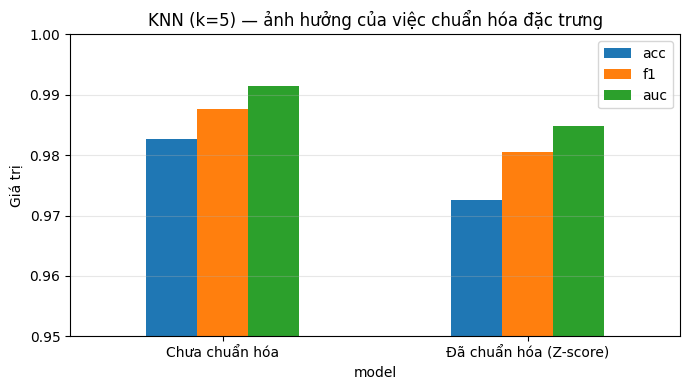

In [5]:
# KNN quyết định bằng KHOẢNG CÁCH, mà khoảng cách cộng dồn hiệu trên mọi
# chiều. Một đặc trưng có đơn vị lớn sẽ áp đảo các đặc trưng đơn vị nhỏ.
# Vì vậy sách vở thường nói "KNN bắt buộc phải chuẩn hóa". Ta ĐO THỬ thay vì
# tin ngay — kết quả trên ba bộ dữ liệu khác nhau không giống nhau.
rows = []
for tag, A, B in [("Chưa chuẩn hóa", X_tr_raw, X_te_raw),
                  ("Đã chuẩn hóa (Z-score)", X_tr, X_te)]:
    yp, ys, _ = fit_knn(A, y_tr, B, n_neighbors=5)
    rows.append(evaluate(y_te, yp, ys, tag))

scale_df = pd.DataFrame(rows).set_index("model").round(4)
print("KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng")
print(scale_df[["acc", "prec", "rec", "f1", "auc"]])
print(f"\nChênh lệch F1: {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(SCALE_COMMENT)

ax = scale_df[["acc", "f1", "auc"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_title("KNN (k=5) — ảnh hưởng của việc chuẩn hóa đặc trưng")
ax.set_ylabel("Giá trị")
ax.set_ylim(SCALE_YLIM)
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Chọn Số Láng Giềng k

       acc    prec     rec      f1     auc
k                                         
1   0.9766  0.9834  0.9832  0.9833  0.9721
3   0.9778  0.9826  0.9857  0.9842  0.9842
5   0.9726  0.9795  0.9814  0.9805  0.9848
7   0.9718  0.9800  0.9797  0.9799  0.9859
9   0.9702  0.9797  0.9777  0.9787  0.9869
11  0.9704  0.9786  0.9792  0.9789  0.9870
15  0.9694  0.9767  0.9797  0.9782  0.9874
21  0.9653  0.9733  0.9774  0.9754  0.9879
31  0.9621  0.9699  0.9763  0.9731  0.9877

→ k tốt nhất theo F1: k = 3  (F1 = 0.9842)
→ F1 tại k = 31: 0.9731

Nhận xét: F1 giảm đều khi k tăng. Điều này cho thấy mã độc không nằm
thành một cụm rộng mà thành NHIỀU NHÓM NHỎ rời rạc — mỗi nhóm là một họ mã
độc hoặc một loại packer. Lấy phiếu trên phạm vi rộng (k lớn) sẽ kéo vào cả
những mẫu thuộc nhóm khác, làm loãng quyết định.


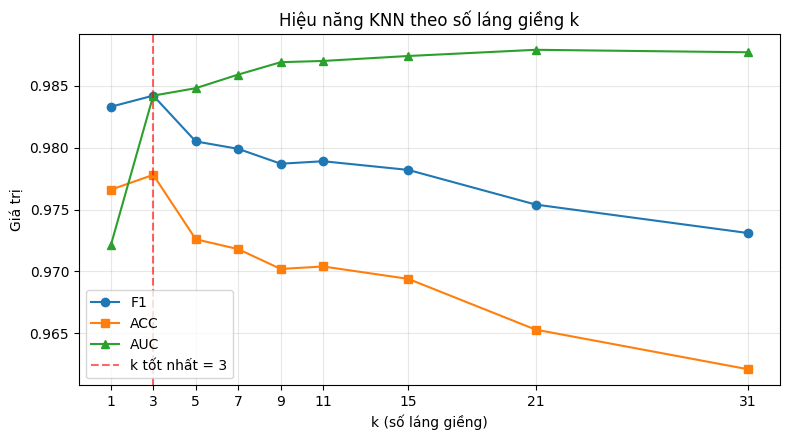

In [6]:
# k nhỏ  → biên quyết định gấp khúc, bám sát từng mẫu  → dễ overfit, nhạy nhiễu
#          (k = 1 nghĩa là mô hình chỉ sao chép nhãn của mẫu gần nhất)
# k lớn  → biên quyết định mượt, lấy ý kiến đa số rộng → dễ underfit, và lớp
#          thiểu số (tấn công) dễ bị lớp đa số lấn át trong phiếu bầu
rows = []
for k in K_GRID:
    yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k)
    rows.append(evaluate(y_te, yp, ys, k))

k_df = pd.DataFrame(rows).set_index("model").round(4)
k_df.index.name = "k"
print(k_df[["acc", "prec", "rec", "f1", "auc"]])

k_best = int(k_df["f1"].idxmax())
print(f"\n→ k tốt nhất theo F1: k = {k_best}  (F1 = {k_df.loc[k_best, 'f1']:.4f})")
print(f"→ F1 tại k = {K_GRID[-1]}: {k_df['f1'].iloc[-1]:.4f}")
print(KSWEEP_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, mk in [("f1", "o"), ("acc", "s"), ("auc", "^")]:
    ax.plot(k_df.index, k_df[col], marker=mk, label=col.upper())
ax.axvline(k_best, color="red", ls="--", alpha=.6, label=f"k tốt nhất = {k_best}")
ax.set_xlabel("k (số láng giềng)")
ax.set_ylabel("Giá trị")
ax.set_title("Hiệu năng KNN theo số láng giềng k")
ax.set_xticks(K_GRID)
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. So Sánh Metric Khoảng Cách & Trọng Số Phiếu

KNN k=3 — so sánh 3 metric × 2 kiểu trọng số
                       acc    prec     rec      f1     auc
model                                                     
manhattan|distance  0.9816  0.9858  0.9880  0.9869  0.9854
manhattan|uniform   0.9802  0.9843  0.9874  0.9859  0.9858
euclidean|distance  0.9786  0.9838  0.9857  0.9847  0.9840
euclidean|uniform   0.9778  0.9826  0.9857  0.9842  0.9842
chebyshev|distance  0.9726  0.9795  0.9814  0.9805  0.9809
chebyshev|uniform   0.9716  0.9773  0.9823  0.9798  0.9810

→ Cấu hình tốt nhất: metric=manhattan, weights=distance  (F1 = 0.9869)

Nhận xét: manhattan + distance cho kết quả tốt nhất. Trọng số 1/d giúp
mẫu cùng họ mã độc (ở rất gần) có tiếng nói lớn hơn mẫu ở rìa cụm.


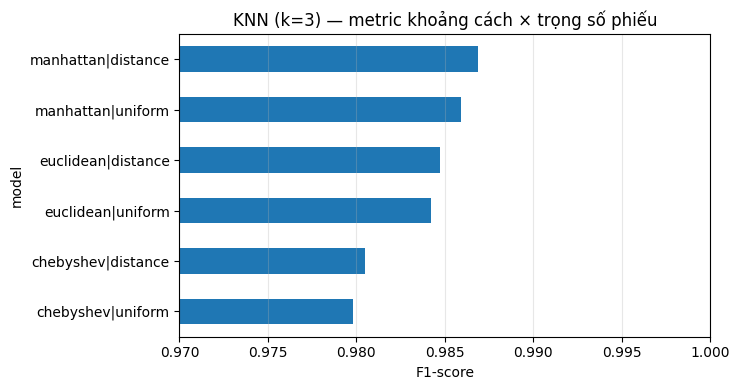

In [7]:
# euclidean (L2) : căn bậc hai tổng bình phương hiệu
# manhattan (L1) : tổng trị tuyệt đối hiệu — bền hơn với ngoại lai và theo
#                  thực nghiệm thường tốt hơn L2 khi số chiều cao
# chebyshev (L∞) : chỉ lấy hiệu lớn nhất trên một chiều, bỏ qua các chiều khác
#
# weights='uniform'  : mọi láng giềng một phiếu bằng nhau
# weights='distance' : láng giềng càng gần phiếu càng nặng, theo tỷ lệ 1/d
rows = []
for met in METRICS:
    for w in WEIGHTS:
        yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best,
                            metric=met, weights=w)
        rows.append(evaluate(y_te, yp, ys, f"{met}|{w}"))

combo_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"KNN k={k_best} — so sánh {len(METRICS)} metric × {len(WEIGHTS)} kiểu trọng số")
print(combo_df[["acc", "prec", "rec", "f1", "auc"]].sort_values("f1", ascending=False))

combo_best = combo_df["f1"].idxmax()
best_metric, best_weights = combo_best.split("|")
print(f"\n→ Cấu hình tốt nhất: metric={best_metric}, weights={best_weights}"
      f"  (F1 = {combo_df.loc[combo_best, 'f1']:.4f})")
print(COMBO_COMMENT)

ax = combo_df["f1"].sort_values().plot.barh(figsize=(7.5, 4))
ax.set_xlabel("F1-score")
ax.set_title(f"KNN (k={k_best}) — metric khoảng cách × trọng số phiếu")
ax.set_xlim(COMBO_XLIM)
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Số Chiều & Lời Nguyền Số Chiều (PCA)

evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều
                  f1     auc     evr
n_components                        
2             0.9206  0.9158  0.1730
5             0.9802  0.9823  0.3166
10            0.9807  0.9806  0.4704
20            0.9829  0.9848  0.6589
69            0.9842  0.9842  1.0000

Nhận xét: khác với CV4.1, ở đây PCA KHÔNG giúp gì — dùng đủ số chiều mới
cho F1 cao nhất. Thông tin phân biệt mã độc nằm rải trên nhiều đặc trưng
header, và PCA giữ phương sai chứ không giữ thông tin phân biệt lớp.


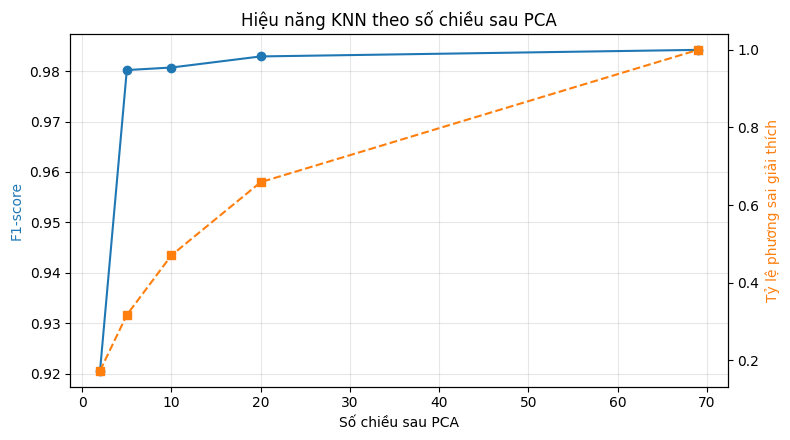

In [8]:
# Lời nguyền số chiều: khi số chiều tăng, khoảng cách từ một điểm tới mẫu gần
# nhất và tới mẫu xa nhất co lại gần bằng nhau → khái niệm "láng giềng" mất
# dần ý nghĩa, đồng thời chi phí tính khoảng cách tăng lên.
# PCA chiếu dữ liệu sang không gian ít chiều hơn mà vẫn giữ phần lớn phương sai.
rows = []
for nc in PCA_GRID:
    if nc >= X_tr.shape[1]:
        continue
    pca = PCA(n_components=nc, random_state=SEED).fit(X_tr)
    yp, ys, _ = fit_knn(pca.transform(X_tr), y_tr, pca.transform(X_te),
                        n_neighbors=k_best)
    r = evaluate(y_te, yp, ys, nc)
    r["evr"] = pca.explained_variance_ratio_.sum()
    rows.append(r)

# Mốc so sánh: dùng toàn bộ số chiều
yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best)
r = evaluate(y_te, yp, ys, X_tr.shape[1])
r["evr"] = 1.0
rows.append(r)

pca_df = pd.DataFrame(rows).set_index("model").round(4)
pca_df.index.name = "n_components"
print("evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều")
print(pca_df[["f1", "auc", "evr"]])
print(PCA_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(pca_df.index, pca_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.set_xlabel("Số chiều sau PCA")
ax1.set_ylabel("F1-score", color="tab:blue")
ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.plot(pca_df.index, pca_df["evr"], marker="s", ls="--", color="tab:orange")
ax2.set_ylabel("Tỷ lệ phương sai giải thích", color="tab:orange")
ax1.set_title("Hiệu năng KNN theo số chiều sau PCA")
plt.tight_layout()
plt.show()


### A6. Độ Trễ Suy Luận – Điểm Yếu Cốt Tử Của KNN

         ms_per_sample  samples_per_sec  mem_train_MB
n_train                                              
1000             0.125         7985.090         0.526
5000             0.141         7101.625         2.632
10000            0.117         8520.722         5.264
11648            0.109         9145.240         6.132

⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:
  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train
  phải nằm trong bộ nhớ khi triển khai.

Nhận xét: một hãng antivirus triển khai KNN sẽ phải gửi kèm TOÀN BỘ tập
mẫu tới máy khách và quét lại tập đó cho mỗi file cần kiểm tra. Với cơ sở
dữ liệu hàng triệu mẫu, điều này bất khả thi về cả băng thông, bộ nhớ và
thời gian — đó là lý do thực tế quan trọng hơn cả độ chính xác.


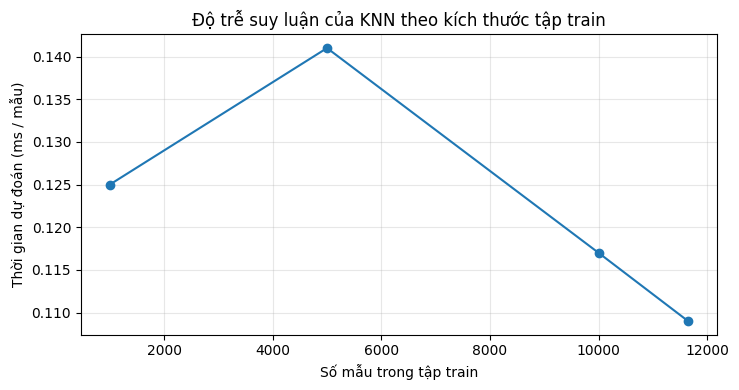

In [9]:
# KNN là "lazy learner": fit() gần như tức thì vì chỉ lưu dữ liệu, nhưng mỗi
# lần predict() phải đi tìm láng giềng trong TOÀN BỘ tập train. Chi phí suy
# luận vì thế tăng theo kích thước tập train — ngược hẳn với cây quyết định
# hay hồi quy logistic, nơi chi phí dự đoán là hằng số.
N_PROBE = 2000     # số mẫu dùng để đo thời gian
rows = []
for n in [1000, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    kn = KNeighborsClassifier(n_neighbors=k_best).fit(X_tr[:n], y_tr[:n])
    t0 = time.perf_counter()
    kn.predict(X_te[:N_PROBE])
    dt = time.perf_counter() - t0
    rows.append({"n_train": n,
                 "ms_per_sample": dt / N_PROBE * 1000,
                 "samples_per_sec": N_PROBE / dt,
                 "mem_train_MB": X_tr[:n].nbytes / 1024 / 1024})

lat_df = pd.DataFrame(rows).set_index("n_train").round(3)
print(lat_df)
print("\n⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:")
print("  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train")
print("  phải nằm trong bộ nhớ khi triển khai.")
print(LATENCY_COMMENT)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(lat_df.index, lat_df["ms_per_sample"], marker="o")
ax.set_xlabel("Số mẫu trong tập train")
ax.set_ylabel("Thời gian dự đoán (ms / mẫu)")
ax.set_title("Độ trễ suy luận của KNN theo kích thước tập train")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Mô Hình Cuối – Confusion Matrix & Đường Cong ROC

                                   acc    prec    rec      f1  f1_macro  \
model                                                                     
KNN (k=3, manhattan, distance)  0.9816  0.9858  0.988  0.9869    0.9780   
Random Forest (200 cây)         0.9912  0.9895  0.998  0.9937    0.9894   

                                   auc  
model                                   
KNN (k=3, manhattan, distance)  0.9854  
Random Forest (200 cây)         0.9983  

Confusion matrix KNN:  TN=1440  FP=50  FN=42  TP=3460
  FP = 50 cảnh báo giả | FN = 42 lần bỏ sót malware

              precision    recall  f1-score   support

      Benign     0.9717    0.9664    0.9690      1490
     Malware     0.9858    0.9880    0.9869      3502

    accuracy                         0.9816      4992
   macro avg     0.9787    0.9772    0.9780      4992
weighted avg     0.9815    0.9816    0.9816      4992


Nhận xét: Random Forest vượt KNN ở cả F1 và đặc biệt AUC. Với sản phẩm
diệt virus, False Positive (

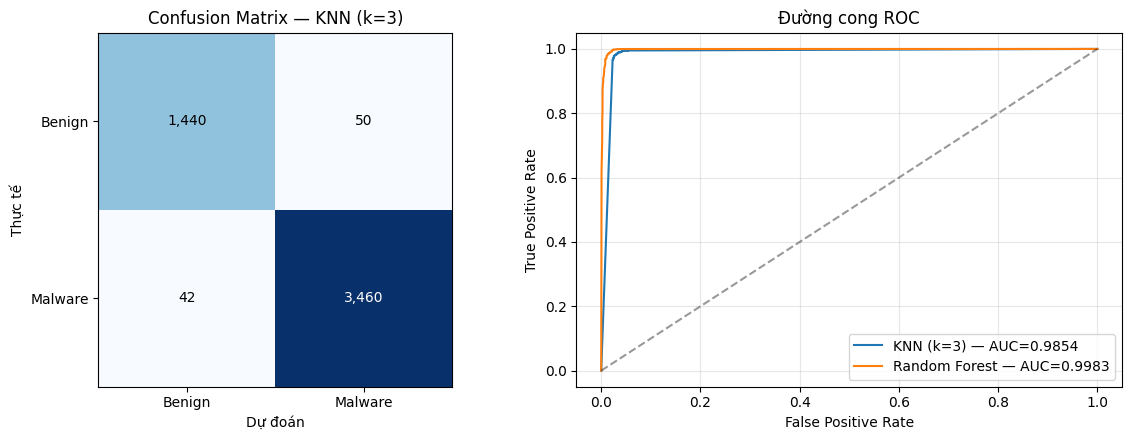

In [10]:
# Mô hình cuối dùng k, metric và weights tốt nhất đã tìm được ở A3 và A4.
# Random Forest 200 cây được huấn luyện trên cùng tập train để làm mốc so sánh.
y_pred, y_score, knn_final = fit_knn(
    X_tr, y_tr, X_te,
    n_neighbors=k_best, metric=best_metric, weights=best_weights)
knn_res = evaluate(y_te, y_pred, y_score,
                   f"KNN (k={k_best}, {best_metric}, {best_weights})")

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([knn_res, rf_res]).set_index("model").round(4)
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix KNN:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], TARGET_NAMES)
axes[0].set_yticks([0, 1], TARGET_NAMES)
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")
axes[0].set_title(f"Confusion Matrix — KNN (k={k_best})")

for nm, sc in [(f"KNN (k={k_best})", y_score), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

F1 từng fold : [0.9851 0.9878 0.9861 0.9846 0.9865]
F1 trung bình: 0.9860 ± 0.0011
F1 của một lần chia train/test ở A7: 0.9869

Nhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định. Lưu ý rằng con số này
chỉ đáng tin vì ta đã lọc trùng ở A1; nếu còn dòng trùng thì cross-validation
cũng bị thổi phồng y như một lần chia đơn lẻ.


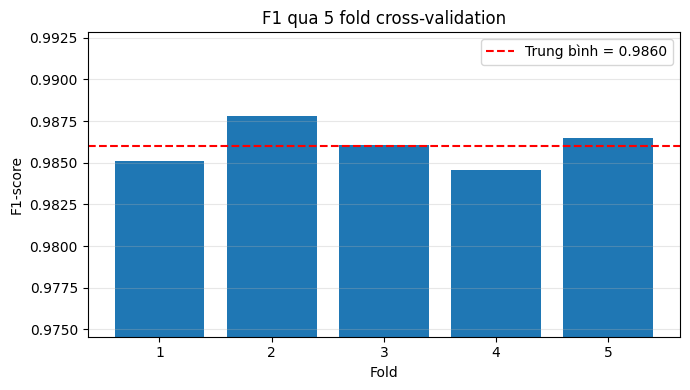

In [11]:
# Một lần chia train/test có thể "may mắn". K-fold chia dữ liệu thành k phần,
# lần lượt lấy một phần làm test → k kết quả, xem độ lệch chuẩn để biết mô
# hình có ổn định hay không.
#
# Scaler PHẢI nằm trong Pipeline: mỗi fold tự fit scaler trên phần train của
# riêng fold đó. Nếu chuẩn hóa toàn bộ dữ liệu rồi mới chia fold thì thông tin
# của fold validation đã rò rỉ vào scaler.
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=k_best, metric=best_metric,
                                 weights=best_weights)),
])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)

print(f"F1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: {knn_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.01, max(scores) + 0.005)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Trên bộ PE header, chuẩn hóa Z-score *làm giảm* F1 — ngược hẳn quy tắc thông thường.
2. Bước lọc trùng (và thứ tự bỏ cột hash trước khi lọc) là điều kiện cần để kết quả đánh giá đáng tin.
3. `k` nhỏ thắng và F1 giảm đều khi `k` tăng — mã độc nằm thành nhiều nhóm nhỏ rời rạc theo họ và theo packer.
4. PCA không giúp ích: thông tin phân biệt nằm rải trên nhiều đặc trưng header.
5. Random Forest vượt KNN ở cả F1 và AUC, và quan trọng hơn là không phải mang theo toàn bộ tập mẫu khi triển khai.

**Câu hỏi thảo luận**

1. Xem lại bảng ở phần A2: khi một vài đặc trưng biên độ lớn (`SizeOfImage`, `ImageBase`, `CheckSum`) đúng là những đặc trưng phân biệt tốt nhất, việc đưa mọi đặc trưng về cùng thang đo gây ra điều gì?
2. Nếu *không* bỏ cột hash trước khi gọi `drop_duplicates()` thì sẽ xảy ra chuyện gì? Và vì sao dòng trùng lặp lại đặc biệt nguy hiểm với KNN khi chia train/test ngẫu nhiên?
3. F1 giảm đều khi `k` tăng nói gì về cấu trúc của dữ liệu mã độc?
4. `SectionMaxEntropy` bị loại vì phương sai bằng 0, dù lý thuyết coi entropy là chỉ báo mạnh của việc đóng gói file. Hãy tra lại giá trị cột này trong dữ liệu gốc và giải thích vì sao nó vô dụng ở đây.
5. Ngoài độ chính xác, hãy nêu hai lý do thực tế khiến một hãng antivirus sẽ không chọn KNN cho sản phẩm thương mại.
6. Mô hình cuối báo giả một số file lành tính (FP). Với sản phẩm diệt virus, một FP có hậu quả gì so với một FN? Nên điều chỉnh ngưỡng theo hướng nào?
